# ___Shape files___
--------------------

In [1]:
!python --version

Python 3.15.2


The system cannot find the path specified.


In [62]:
# Australian digital boundary shapefiles
# https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/edition-4-july-2026-june-2031/access-and-downloads/digital-boundary-files

In [31]:
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

In [5]:
postal = gpd.read_file(r"../../data/maps/POA_2026_AUS_SHP_GDA2020/POA_2026_AUST_GDA2020.shp") # postal areas

In [6]:
postal

,POA_CODE26,POA_NAME26,AUS_CODE26,AUS_NAME26,AREASQKM26,geometry
0,0800,0800,AUS,Australia,3.1731,"POLYGON ((130.83681 -12.45376, 130.83684 -12.4..."
1,0810,0810,AUS,Australia,24.4283,"POLYGON ((130.89986 -12.36567, 130.89875 -12.3..."
2,0812,0812,AUS,Australia,35.8900,"POLYGON ((130.91915 -12.40786, 130.91831 -12.4..."
3,0820,0820,AUS,Australia,48.8175,"POLYGON ((130.90736 -12.42754, 130.90765 -12.4..."
4,0822,0822,AUS,Australia,150766.0517,"MULTIPOLYGON (((136.69376 -11.13994, 136.69036..."
...,...,...,...,...,...,...
2640,7469,7469,AUS,Australia,5892.5577,"MULTIPOLYGON (((144.76423 -41.43596, 144.76422..."
2641,7470,7470,AUS,Australia,109.2037,"POLYGON ((145.57769 -41.7864, 145.57686 -41.78..."
2642,9494,No usual address (Aust),AUS,Australia,NaN,None
2643,9797,Migratory - Offshore - Shipping (Aust),AUS,Australia,NaN,None


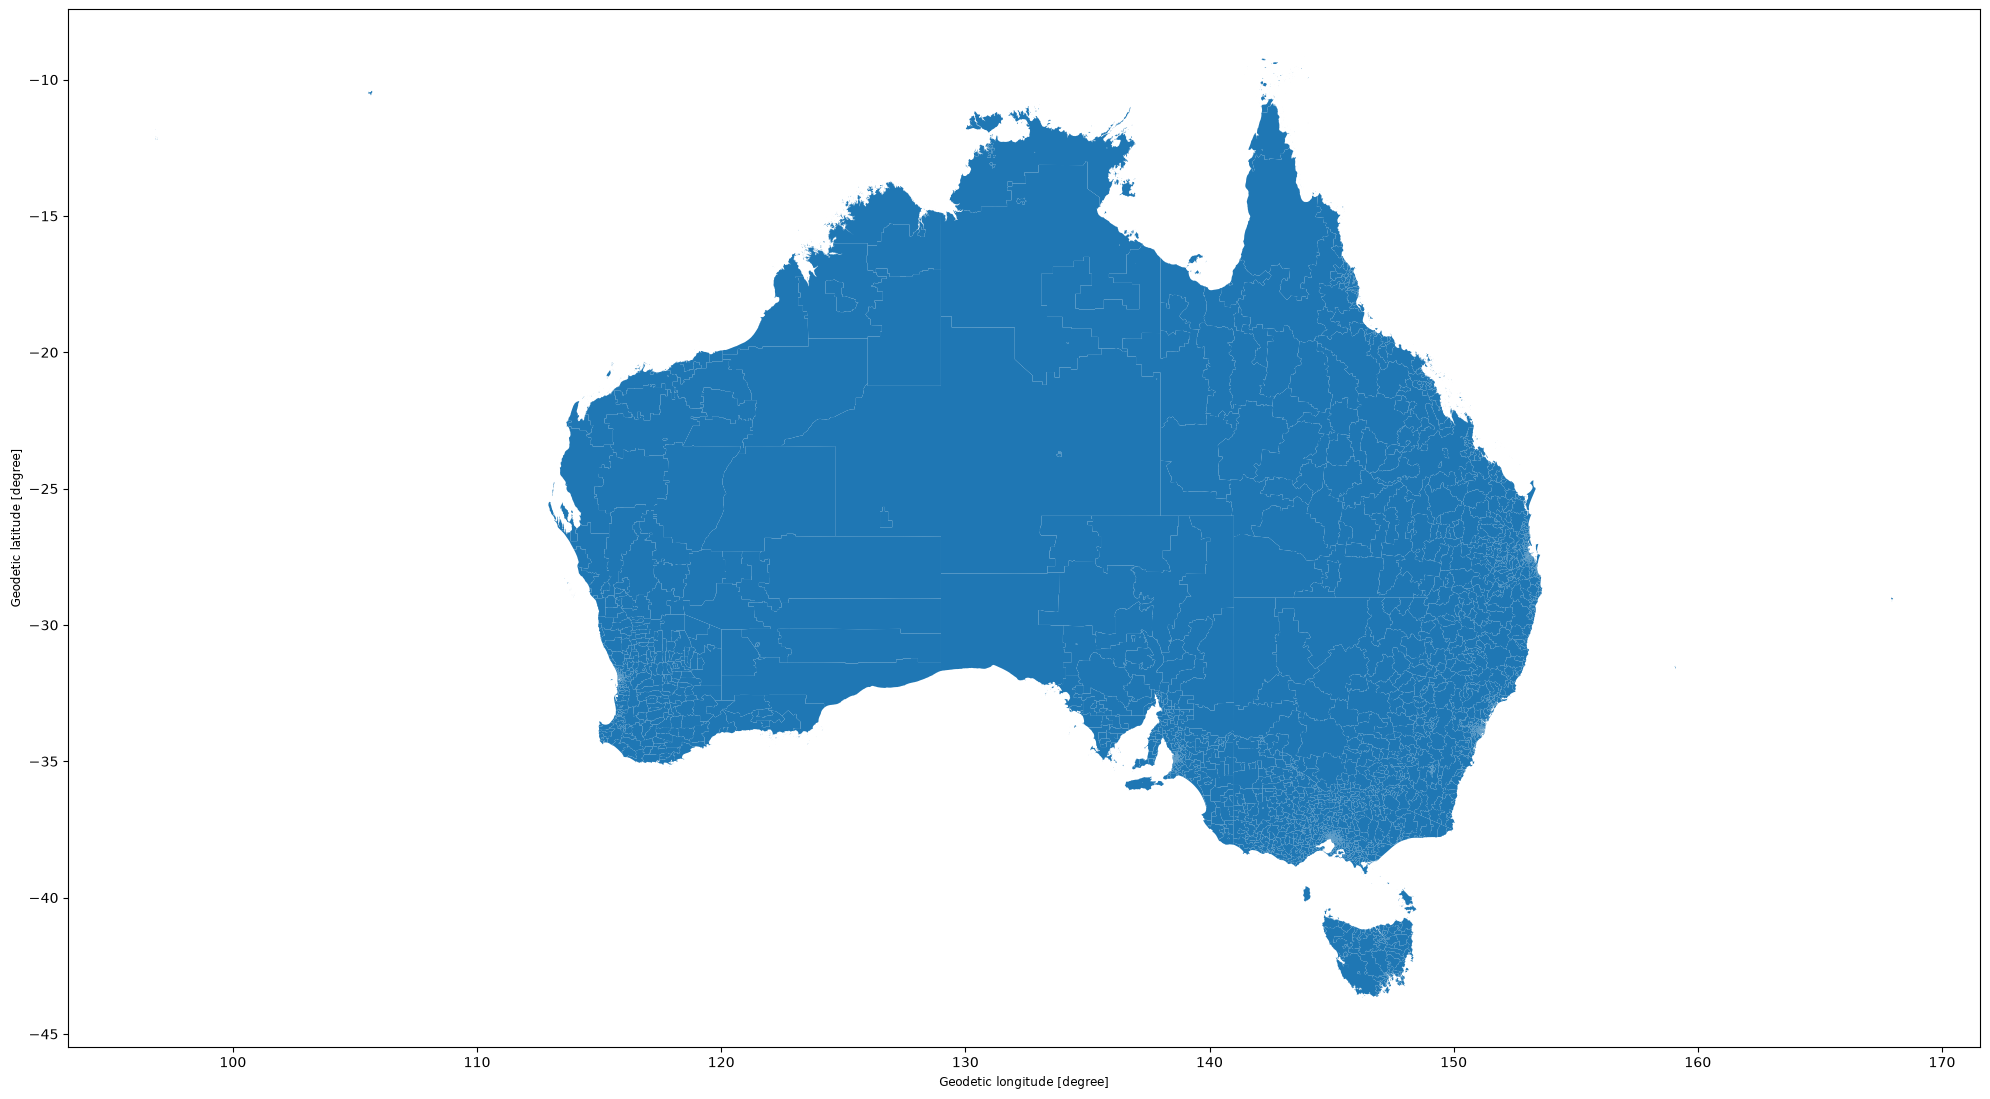

In [15]:
fig, axes = plt.subplots()
fig.set_size_inches(20, 14)
postal.plot(ax = axes)
plt.tight_layout()
plt.show() # looks very detailed :)

In [7]:
states = gpd.read_file(r"../../data/maps/STE_2026_AUST_SHP_GDA2020/STE_2026_AUST_GDA2020.shp") # states & territories

In [8]:
states

,STE_CODE26,STE_NAME26,CHG_FLAG26,CHG_LBL26,AUS_CODE26,AUS_NAME26,AREASQKM26,geometry
0,1,New South Wales,0,No change,AUS,Australia,8.007977e+05,"MULTIPOLYGON (((153.57106 -28.87381, 153.57106..."
1,2,Victoria,0,No change,AUS,Australia,2.274963e+05,"MULTIPOLYGON (((145.28914 -38.4551, 145.28908 ..."
2,3,Queensland,0,No change,AUS,Australia,1.730173e+06,"MULTIPOLYGON (((153.39723 -27.34369, 153.39721..."
3,4,South Australia,0,No change,AUS,Australia,9.842293e+05,"MULTIPOLYGON (((135.03119 -34.77965, 135.03115..."
4,5,Western Australia,0,No change,AUS,Australia,2.526633e+06,"MULTIPOLYGON (((113.40821 -24.49047, 113.40772..."
5,6,Tasmania,0,No change,AUS,Australia,6.801756e+04,"MULTIPOLYGON (((147.09918 -43.24477, 147.09914..."
6,7,Northern Territory,0,No change,AUS,Australia,1.348135e+06,"MULTIPOLYGON (((136.69376 -11.13994, 136.69036..."
7,8,Australian Capital Territory,0,No change,AUS,Australia,2.358133e+03,"POLYGON ((149.10835 -35.58397, 149.09495 -35.5..."
8,9,Other Territories,0,No change,AUS,Australia,2.557420e+02,"MULTIPOLYGON (((167.9453 -29.00073, 167.94523 ..."
9,Z,Outside Australia,0,No change,ZZZ,Outside Australia,NaN,None


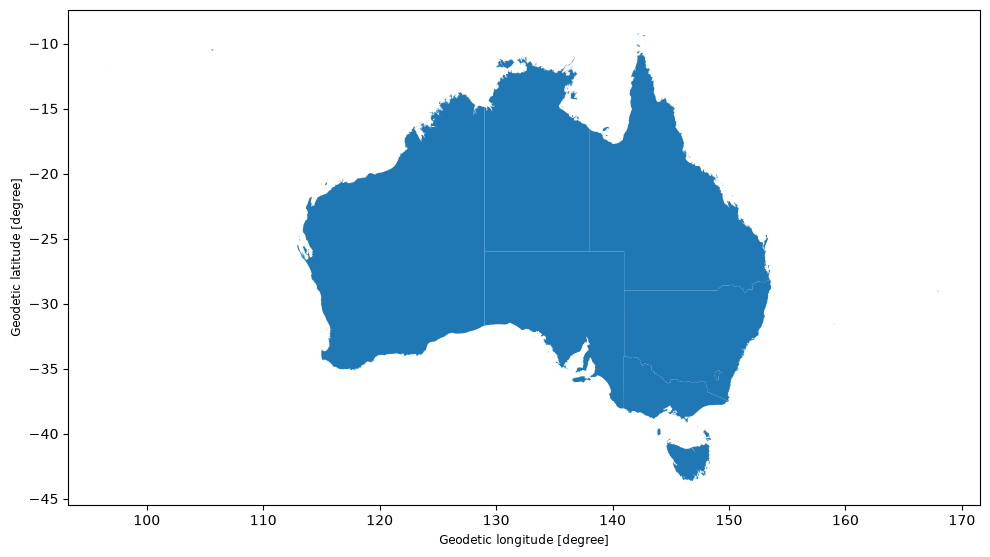

In [9]:
fig, axes = plt.subplots()
fig.set_size_inches(10, 7)
states.plot(ax = axes)
plt.tight_layout()
plt.show() 

In [56]:
states#.loc[0, :]

,STE_CODE26,STE_NAME26,CHG_FLAG26,CHG_LBL26,AUS_CODE26,AUS_NAME26,AREASQKM26,geometry
0,1,New South Wales,0,No change,AUS,Australia,8.007977e+05,"MULTIPOLYGON (((153.57106 -28.87381, 153.57106..."
1,2,Victoria,0,No change,AUS,Australia,2.274963e+05,"MULTIPOLYGON (((145.28914 -38.4551, 145.28908 ..."
2,3,Queensland,0,No change,AUS,Australia,1.730173e+06,"MULTIPOLYGON (((153.39723 -27.34369, 153.39721..."
3,4,South Australia,0,No change,AUS,Australia,9.842293e+05,"MULTIPOLYGON (((135.03119 -34.77965, 135.03115..."
4,5,Western Australia,0,No change,AUS,Australia,2.526633e+06,"MULTIPOLYGON (((113.40821 -24.49047, 113.40772..."
5,6,Tasmania,0,No change,AUS,Australia,6.801756e+04,"MULTIPOLYGON (((147.09918 -43.24477, 147.09914..."
6,7,Northern Territory,0,No change,AUS,Australia,1.348135e+06,"MULTIPOLYGON (((136.69376 -11.13994, 136.69036..."
7,8,Australian Capital Territory,0,No change,AUS,Australia,2.358133e+03,"POLYGON ((149.10835 -35.58397, 149.09495 -35.5..."
8,9,Other Territories,0,No change,AUS,Australia,2.557420e+02,"MULTIPOLYGON (((167.9453 -29.00073, 167.94523 ..."
9,Z,Outside Australia,0,No change,ZZZ,Outside Australia,NaN,None


In [24]:
type(states.loc[0, "geometry"]) # MultiPolygon is a collection of Polygons - https://shapely.readthedocs.io/en/stable/reference/shapely.MultiPolygon.html

shapely.geometry.multipolygon.MultiPolygon

In [53]:
# the MultiPolygon.geoms will yield the polygons its composed of

polygons_nsw = [g for g in states.loc[0, "geometry"].geoms] # number of geoms NSW's multipolygon is composed of
assert all([isinstance(p, shapely.Polygon) for p in polygons_nsw]) # make sure there is no MultiPolygon in this list 

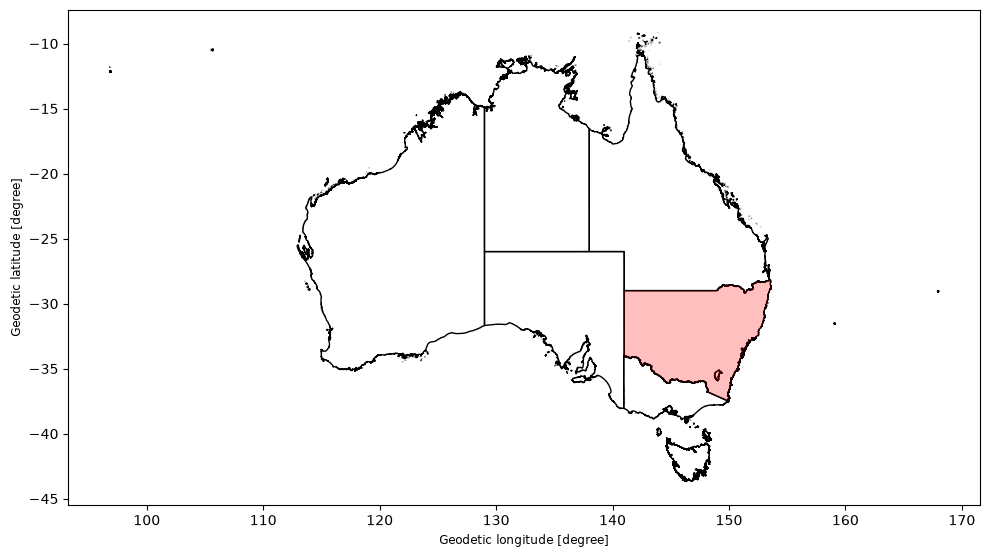

In [61]:
# try and plot the NSW polygons in a different colour
# we need to create matplotlib.patches.Polygon from shapely.Polygon

mpl_polygons_nsw = PatchCollection([Polygon(xy=np.stack(p.exterior.coords.xy, axis = 1))#, facecolor="red", edgecolor="black", alpha=0.5, fill=True) # setting these attributes to each individual object inside the collection does not work with PatchCollection class
                                        for p in polygons_nsw]) # converted polygons
mpl_polygons_nsw.set_facecolor("red")
mpl_polygons_nsw.set_alpha(0.25)
mpl_polygons_nsw.set_edgecolor("black")

fig, axes = plt.subplots()
fig.set_size_inches(10, 7)
states.plot(ax = axes, color="none") # all the states
axes.add_collection(mpl_polygons_nsw) # add the patch collection to the axes
plt.tight_layout()
plt.show()

In [10]:
postal.POA_CODE26.replace("ZZZZ", '0').astype(np.int64) # convert the postal codes to integers

0        800
1        810
2        812
3        820
4        822
        ... 
2640    7469
2641    7470
2642    9494
2643    9797
2644       0
Name: POA_CODE26, Length: 2645, dtype: int64

In [34]:
offsets = np.where((postal.POA_CODE26.replace("ZZZZ", '0').astype(np.int64) > 2700) & (postal.POA_CODE26.replace("ZZZZ", '0').astype(np.int64) < 2800))[0] # in exclusive range [2700, 2800]
offsets

array([527, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538, 539,
       540, 541, 542, 543, 544, 545, 546, 547, 548, 549, 550, 551, 552,
       553, 554, 555, 556, 557, 558, 559, 560, 561, 562, 563, 564, 565,
       566, 567, 568, 569, 570, 571, 572, 573, 574, 575, 576, 577, 578,
       579, 580, 581, 582, 583, 584, 585, 586, 587, 588, 589, 590, 591,
       592, 593, 594, 595, 596, 597, 598, 599, 600, 601, 602])

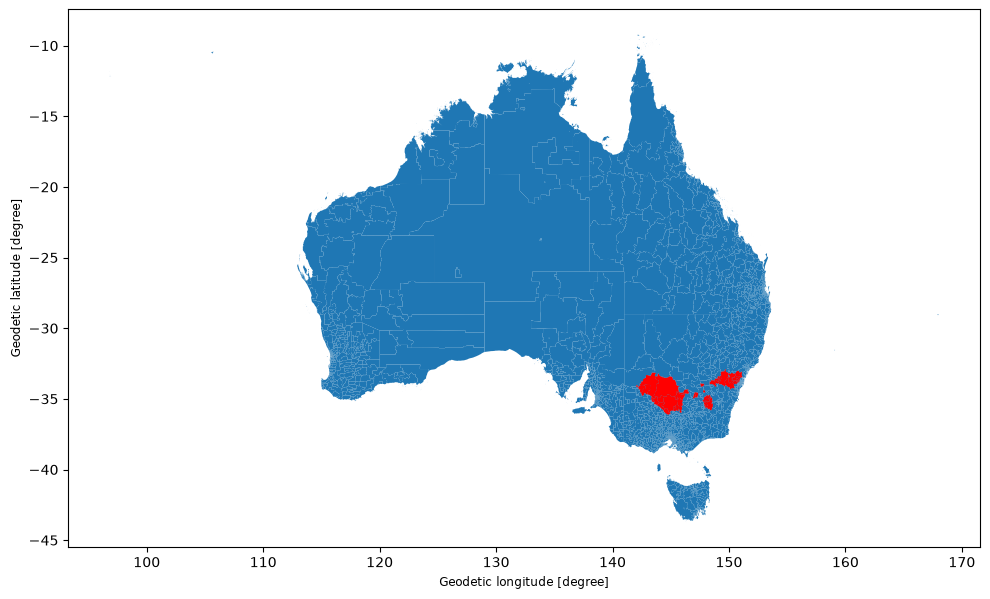

In [43]:
fig, axes = plt.subplots()
fig.set_size_inches(10, 7)
# axes.grid()
axes.set_axisbelow(True)

postal.plot(ax = axes)
postal.iloc[offsets, ].plot(ax = axes, color = "red") # [2700, 2800] - colour them in Red

plt.tight_layout()
# plt.show()
plt.savefig(r"../../plots/postal-2700-2800.png", dpi = 1000, format = "png")

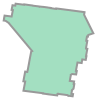

In [55]:
postal.loc[offsets, "geometry"].values[0]

In [54]:
type(postal.loc[offsets, "geometry"].values[0])

shapely.geometry.polygon.Polygon

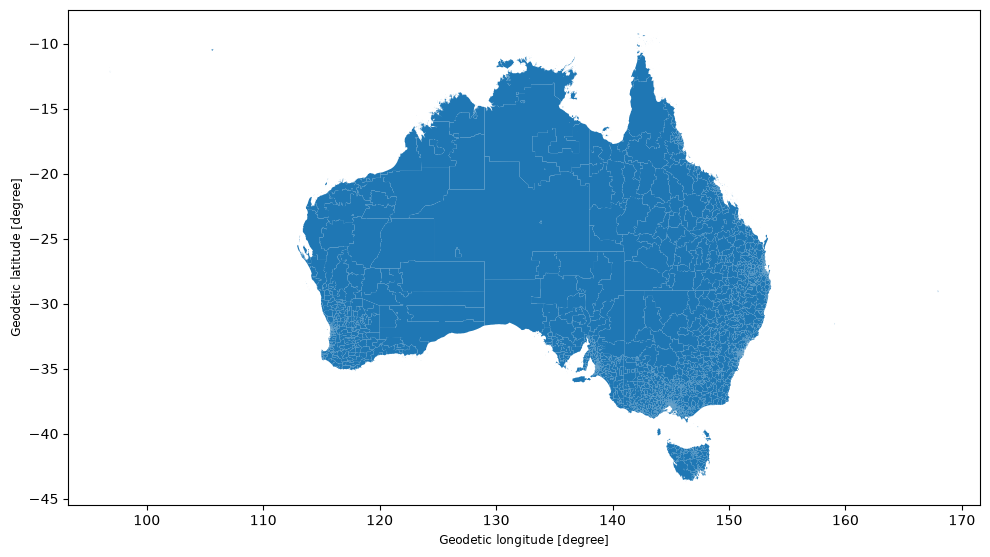

In [56]:
fig, axes = plt.subplots()
fig.set_size_inches(10, 7)
axes.set_axisbelow(True)

postal.plot(ax = axes)
plt.tight_layout()
# plt.show()

In [70]:
dir(postal.loc[offsets, "geometry"].values[0]) # attributes of a Shapely.Polygon class object

['__and__',
 '__bool__',
 '__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__geo_interface__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__or__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__slots__',
 '__static_attributes__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 '__xor__',
 '_geom',
 '_geom_prepared',
 '_line_interpolate_point',
 '_ndim',
 '_repr_svg_',
 'area',
 'boundary',
 'bounds',
 'buffer',
 'centroid',
 'contains',
 'contains_properly',
 'convex_hull',
 'coords',
 'covered_by',
 'covers',
 'crosses',
 'difference',
 'disjoint',
 'distance',
 'dwithin',
 'envelope',
 'equals',
 'equals_exact',
 'exterior',
 'from_bounds',
 'geom_type',
 'geometryType',
 'has_m',
 'has_z',
 'hausdorff_distance',
 'interiors',
 'interpolate',
 'intersection',


In [75]:
postal.loc[offsets, "geometry"].values[0].exterior.coords.xy # Shapely.Polygon.exterior yields the outer boundary of the polygon and ..exterior.coords.xy yields the x y coordinates of the polygon's outer boundary

(array('d', [147.20010591, 147.20027352, 147.20006752, 147.22128017, 147.22166415, 147.22209011, 147.22944099, 147.25572457, 147.25756355, 147.28352708, 147.28666199, 147.30100576, 147.33469533, 147.33523425, 147.33508423, 147.33333935, 147.33673754, 147.33855936, 147.33857834, 147.34457839, 147.35235443, 147.36073241, 147.37047028, 147.37002491, 147.35519488, 147.35012492, 147.34870489, 147.3486689, 147.3450189, 147.34305593, 147.3433149, 147.34277992, 147.3421469, 147.34636393, 147.3456609, 147.34521889, 147.34082392, 147.34083089, 147.3408429, 147.3408609, 147.34088491, 147.34091389, 147.34092992, 147.34094689, 147.34096591, 147.3410069, 147.34105292, 147.34107789, 147.34110289, 147.3411579, 147.34121593, 147.34127791, 147.34130988, 147.34134288, 147.3413769, 147.3462469, 147.34646389, 147.3463679, 147.34111087, 147.34286689, 147.34256489, 147.3401099, 147.33989291, 147.3261719, 147.3236819, 147.3208049, 147.3071919, 147.3069779, 147.30393989, 147.30133489, 147.30062288, 147.3041298

In [105]:
np.stack([postal.loc[offsets, "geometry"].values[0].exterior.coords.xy[0], postal.loc[offsets, "geometry"].values[0].exterior.coords.xy[1]], axis=1)

array([[147.20010591, -34.54862673],
       [147.20027352, -34.54864756],
       [147.20006752, -34.54963959],
       [147.22128017, -34.55272842],
       [147.22166415, -34.55070541],
       [147.22209011, -34.55075841],
       [147.22944099, -34.55170235],
       [147.25572457, -34.55507513],
       [147.25756355, -34.55530712],
       [147.28352708, -34.55864391],
       [147.28666199, -34.55904389],
       [147.30100576, -34.56096879],
       [147.33469533, -34.56540948],
       [147.33523425, -34.56548052],
       [147.33508423, -34.56747853],
       [147.33333935, -34.57554059],
       [147.33673754, -34.58243721],
       [147.33855936, -34.5861346 ],
       [147.33857834, -34.5861706 ],
       [147.34457839, -34.59806962],
       [147.35235443, -34.61383163],
       [147.36073241, -34.63066268],
       [147.37047028, -34.65035515],
       [147.37002491, -34.65046598],
       [147.35519488, -34.65543599],
       [147.35012492, -34.65713   ],
       [147.34870489, -34.66360899],
 

In [106]:
# xy arg of matplotlib.patches.Polygon needs to be an array of x, y coords

Polygon(xy=np.stack([postal.loc[offsets, "geometry"].values[0].exterior.coords.xy[0], postal.loc[offsets, "geometry"].values[0].exterior.coords.xy[1]], axis=1)) # okayyy

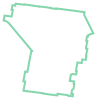

In [110]:
postal.loc[offsets, "geometry"].values[0].exterior

AttributeError: 'MultiPolygon' object has no attribute 'exterior'

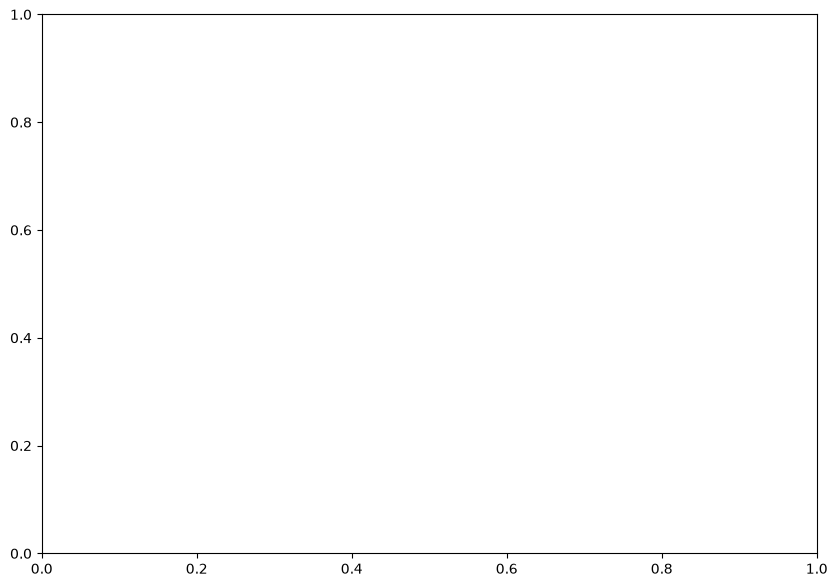

In [111]:
fig, axes = plt.subplots()
fig.set_size_inches(10, 7)

polygons = [Polygon(xy=np.stack([pol.exterior.coords.xy[0], # X coords
                                 pol.exterior.coords.xy[1]], # Y coords
                                 axis=1)) for pol in postal.loc[offsets, "geometry"].values]

plt.tight_layout()
plt.show()

In [114]:
set([type(pol) for pol in postal.loc[offsets, "geometry"].values]) # there are some MultiPolygon objects which do not have an exterior attribute

{shapely.geometry.multipolygon.MultiPolygon, shapely.geometry.polygon.Polygon}

In [81]:
postal.shape # 2645 postal codes

(2645, 6)

In [80]:
postal.sort_values(by="AREASQKM26", ascending=False).reset_index(drop=True).loc[:100, ]

,POA_CODE26,POA_NAME26,AUS_CODE26,AUS_NAME26,AREASQKM26,geometry
0,0872,0872,AUS,Australia,989085.5433,"POLYGON ((132.00215 -28.12001, 131.00108 -28.1..."
1,0852,0852,AUS,Australia,441673.3118,"MULTIPOLYGON (((129.18502 -15.18881, 129.18467..."
2,5690,5690,AUS,Australia,191147.0002,"MULTIPOLYGON (((133.65797 -32.14875, 133.65695..."
3,6646,6646,AUS,Australia,181297.3398,"POLYGON ((121.64898 -27.29024, 121.62512 -27.2..."
4,6440,6440,AUS,Australia,179993.9726,"POLYGON ((122.88415 -29.02978, 122.76755 -29.0..."
...,...,...,...,...,...,...
96,6612,6612,AUS,Australia,12610.7729,"POLYGON ((116.81391 -29.99546, 116.80508 -29.9..."
97,4420,4420,AUS,Australia,12411.7443,"POLYGON ((149.89593 -25.81882, 149.89566 -25.8..."
98,2839,2839,AUS,Australia,12282.8392,"POLYGON ((146.87083 -30.57305, 146.87023 -30.5..."
99,6437,6437,AUS,Australia,11582.6005,"POLYGON ((120.82762 -27.74358, 120.82767 -27.7..."
